In [ ]:
import pandas as pd, matplotlib.pyplot as plt

al = pd.read_csv("al_sde_split_grid.csv")
svts = pd.read_csv("svts_sde_split_grid.csv")


svts_sorted = svts.sort_values("Delta")
svts_sorted.to_csv("svts_sde_split_ranked_by_delta.csv", index=False)


print("\n=== SVTS+SDE split, ranked by Delta ===")
print(svts_sorted.to_string(index=False))
print("\nBest SVTS+SDE split (lowest Delta):")
print(svts_sorted.iloc[0])

plt.figure(figsize=(7,5))
plt.plot(al.AL_pct, al.Delta, marker='o')
plt.xlabel("AL% (SDE% = 10 - AL%)"); plt.ylabel("Delta")
plt.title("Hybrid AL+SDE: Delta vs Split")
plt.grid(alpha=0.3)
plt.savefig("al_sde_split_delta.png", dpi=200, bbox_inches='tight')
plt.close()

plt.figure(figsize=(8,5))
for a,b in [(1.0,0.0),(0.7,0.3),(0.5,0.5),(0.3,0.7),(0.0,1.0)]:
    sub = svts[(svts.alpha==a) & (svts.beta==b)]
    plt.plot(sub.SVTS_pct, sub.Delta, marker='o', label=f"alpha={a}, beta={b}")
plt.xlabel("SVTS% (SDE% = 10 - SVTS%)"); plt.ylabel("Delta")
plt.title("Hybrid SVTS+SDE: Delta vs Split, by alpha/beta")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("svts_sde_split_delta.png", dpi=200, bbox_inches='tight')
plt.close()

            Method  Converged_RMSD  Converged_Delta
                AL         1.54452          0.09440
  SDE (AL+SDE run)         1.44834          0.09008
  SVTS a=1.0 b=0.0         1.82752          0.11468
  SVTS a=0.7 b=0.3         1.57920          0.09622
  SVTS a=0.5 b=0.5         1.53406          0.09526
  SVTS a=0.3 b=0.7         1.54396          0.09504
  SVTS a=0.0 b=1.0         1.51424          0.09220
SDE (SVTS+SDE run)         1.40650          0.08800


In [3]:
import pandas as pd, matplotlib.pyplot as plt

MAX_N = 317  # point count equivalent to 10% budget (approx, varies slightly per path)

al = pd.read_csv("al_sde_split_grid.csv")
svts = pd.read_csv("svts_sde_split_grid.csv")

al["AL_pts"] = (al.AL_pct / 10 * MAX_N).round().astype(int)
al["SDE_pts"] = (al.SDE_pct / 10 * MAX_N).round().astype(int)
svts["SVTS_pts"] = (svts.SVTS_pct / 10 * MAX_N).round().astype(int)
svts["SDE_pts"] = (svts.SDE_pct / 10 * MAX_N).round().astype(int)

al_sorted = al.sort_values("Delta")
al_sorted.to_csv("al_sde_split_ranked_by_delta.csv", index=False)

svts_sorted = svts.sort_values("Delta")
svts_sorted.to_csv("svts_sde_split_ranked_by_delta.csv", index=False)

print("=== AL+SDE split, ranked by Delta ===")
print(al_sorted.to_string(index=False))
print("\nBest AL+SDE split (lowest Delta):")
print(al_sorted.iloc[0])

print("\n=== SVTS+SDE split, ranked by Delta ===")
print(svts_sorted.to_string(index=False))
print("\nBest SVTS+SDE split (lowest Delta):")
print(svts_sorted.iloc[0])

plt.figure(figsize=(7, 5))
plt.plot(al.AL_pts, al.Delta, marker="o")
plt.xlabel("AL training points (SDE points = total - AL)")
plt.ylabel("Delta")
plt.title("Hybrid AL+SDE: Delta vs AL point count")
plt.grid(alpha=0.3)
plt.savefig("al_sde_split_delta.png", dpi=200, bbox_inches="tight")
plt.close()

plt.figure(figsize=(8, 5))
for a, b in [(1.0, 0.0), (0.7, 0.3), (0.5, 0.5), (0.3, 0.7), (0.0, 1.0)]:
    sub = svts[(svts.alpha == a) & (svts.beta == b)]
    plt.plot(sub.SVTS_pts, sub.Delta, marker="o", label=f"alpha={a}, beta={b}")
plt.xlabel("SVTS training points (SDE points = total - SVTS)")
plt.ylabel("Delta")
plt.title("Hybrid SVTS+SDE: Delta vs SVTS point count, by alpha/beta")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("svts_sde_split_delta.png", dpi=200, bbox_inches="tight")
plt.close()


=== AL+SDE split, ranked by Delta ===
 AL_pct  SDE_pct   RMSD  Delta  AL_pts  SDE_pts
      1        9 1.6598 0.0860      32      285
      2        8 1.6588 0.0861      63      254
      3        7 1.6613 0.0862      95      222
      4        6 1.6703 0.0862     127      190
      6        4 1.6789 0.0871     190      127
      9        1 1.6865 0.0874     285       32
      8        2 1.6800 0.0876     254       63
      7        3 1.6990 0.0878     222       95
      5        5 1.7230 0.0885     158      158

Best AL+SDE split (lowest Delta):
AL_pct       1.0000
SDE_pct      9.0000
RMSD         1.6598
Delta        0.0860
AL_pts      32.0000
SDE_pts    285.0000
Name: 0, dtype: float64

=== SVTS+SDE split, ranked by Delta ===
 SVTS_pct  SDE_pct  alpha  beta   RMSD  Delta  SVTS_pts  SDE_pts
        1        9    0.0   1.0 1.6533 0.0856        32      285
        3        7    0.5   0.5 1.6512 0.0858        95      222
        1        9    0.7   0.3 1.6641 0.0861        32      285
  

Saved svts_sde_split_delta.png


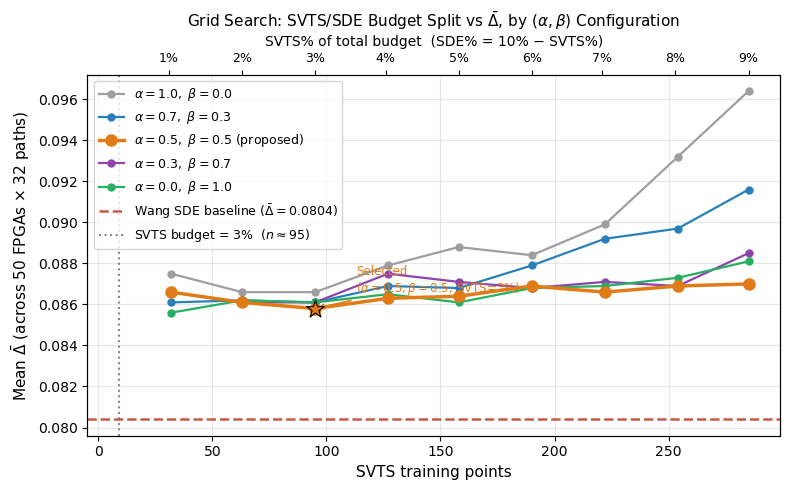

In [1]:
import pandas as pd, matplotlib.pyplot as plt

# svts_sde_split_grid.csv needs columns: SVTS_pct, SDE_pct, alpha, beta, Delta, SVTS_pts
# (generate with grid_search_svts.py or your existing split experiment)
svts = pd.read_csv("svts_sde_split_grid.csv")
MAX_N = 317
svts["SVTS_pts"] = (svts.SVTS_pct / 10 * MAX_N).round().astype(int)

WANG_SDE_DELTA = 0.0804  # reference baseline
BEST_ALPHA, BEST_BETA, BEST_PCT = 0.5, 0.5, 3  # selected operating point

COLORS = {
    (1.0, 0.0): "#9E9E9E",
    (0.7, 0.3): "#2980B9",
    (0.5, 0.5): "#E07B18",
    (0.3, 0.7): "#8E44AD",
    (0.0, 1.0): "#27AE60",
}
LWS = {(0.5, 0.5): 2.5}

fig, ax = plt.subplots(figsize=(8, 5))

for a, b in [(1.0, 0.0), (0.7, 0.3), (0.5, 0.5), (0.3, 0.7), (0.0, 1.0)]:
    sub = svts[(svts.alpha == a) & (svts.beta == b)].sort_values("SVTS_pts")
    lw = LWS.get((a, b), 1.6)
    ms = 8 if (a, b) == (0.5, 0.5) else 5
    ax.plot(
        sub.SVTS_pts,
        sub.Delta,
        color=COLORS[(a, b)],
        marker="o",
        linewidth=lw,
        markersize=ms,
        label=rf"$\alpha={a},\ \beta={b}$"
        + (" (proposed)" if (a, b) == (0.5, 0.5) else ""),
        zorder=6 if (a, b) == (0.5, 0.5) else 3,
    )

# Wang SDE reference
ax.axhline(
    y=WANG_SDE_DELTA,
    color="#C0392B",
    linestyle="--",
    linewidth=1.8,
    label=f"Wang SDE baseline ($\\bar{{\\Delta}}={WANG_SDE_DELTA}$)",
    alpha=0.85,
)

# Selected operating point marker
best_row = svts[
    (svts.alpha == BEST_ALPHA) & (svts.beta == BEST_BETA) & (svts.SVTS_pct == BEST_PCT)
]
if not best_row.empty:
    ax.scatter(
        best_row.SVTS_pts.values[0],
        best_row.Delta.values[0],
        color="#E07B18",
        s=180,
        zorder=10,
        marker="*",
        edgecolors="black",
        linewidths=0.8,
    )
    ax.annotate(
        f"Selected\n($\\alpha=0.5,\\beta=0.5$, SVTS=3%)",
        xy=(best_row.SVTS_pts.values[0], best_row.Delta.values[0]),
        xytext=(best_row.SVTS_pts.values[0] + 18, best_row.Delta.values[0] + 0.0008),
        fontsize=8.5,
        color="#E07B18",
        arrowprops=dict(arrowstyle="->", color="#E07B18", lw=1.2),
    )

# SVTS budget line at 3%
ax.axvline(
    x=int(0.03 * MAX_N),
    color="dimgray",
    linestyle=":",
    linewidth=1.5,
    label=r"SVTS budget = 3%  ($n\approx95$)",
    alpha=0.8,
)

# Top x-axis showing %
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ticks_pts = [int(p / 10 * MAX_N) for p in range(1, 10)]
ax2.set_xticks(ticks_pts)
ax2.set_xticklabels([f"{p}%" for p in range(1, 10)], fontsize=9)
ax2.set_xlabel("SVTS% of total budget  (SDE% = 10% − SVTS%)", fontsize=10)

ax.set_xlabel("SVTS training points", fontsize=11)
ax.set_ylabel(r"Mean $\bar{\Delta}$ (across 50 FPGAs × 32 paths)", fontsize=11)
ax.set_title(
    r"Grid Search: SVTS/SDE Budget Split vs $\bar{\Delta}$, by $(\alpha,\beta)$ Configuration",
    fontsize=11,
)
ax.legend(fontsize=9, loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("svts_sde_split_delta.png", dpi=200, bbox_inches="tight")
print("Saved svts_sde_split_delta.png")


Saved svts_sde_split_delta.png


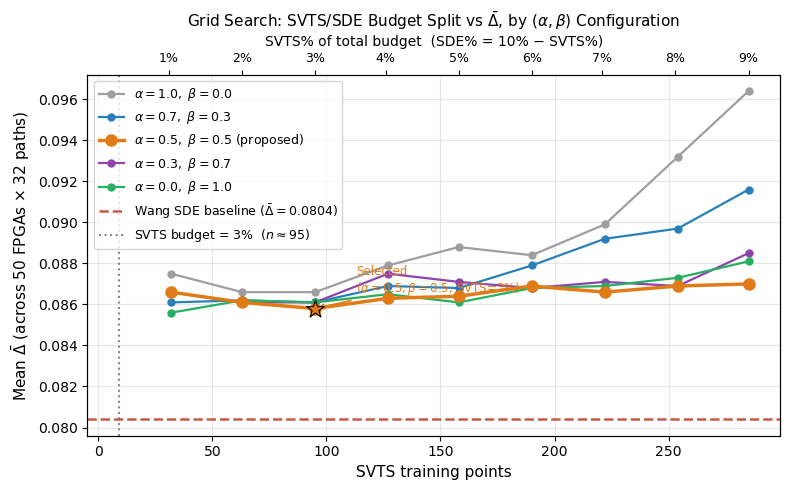

In [2]:
import pandas as pd, matplotlib.pyplot as plt

# svts_sde_split_grid.csv needs columns: SVTS_pct, SDE_pct, alpha, beta, Delta, SVTS_pts
# (generate with grid_search_svts.py or your existing split experiment)
svts = pd.read_csv("svts_sde_split_grid.csv")
MAX_N = 317
svts["SVTS_pts"] = (svts.SVTS_pct / 10 * MAX_N).round().astype(int)

WANG_SDE_DELTA = 0.0804  # reference baseline
BEST_ALPHA, BEST_BETA, BEST_PCT = 0.5, 0.5, 3  # selected operating point

COLORS = {
    (1.0, 0.0): "#9E9E9E",
    (0.7, 0.3): "#2980B9",
    (0.5, 0.5): "#E07B18",
    (0.3, 0.7): "#8E44AD",
    (0.0, 1.0): "#27AE60",
}
LWS = {(0.5, 0.5): 2.5}

fig, ax = plt.subplots(figsize=(8, 5))

for a, b in [(1.0, 0.0), (0.7, 0.3), (0.5, 0.5), (0.3, 0.7), (0.0, 1.0)]:
    sub = svts[(svts.alpha == a) & (svts.beta == b)].sort_values("SVTS_pts")
    lw = LWS.get((a, b), 1.6)
    ms = 8 if (a, b) == (0.5, 0.5) else 5
    ax.plot(
        sub.SVTS_pts,
        sub.Delta,
        color=COLORS[(a, b)],
        marker="o",
        linewidth=lw,
        markersize=ms,
        label=rf"$\alpha={a},\ \beta={b}$"
        + (" (proposed)" if (a, b) == (0.5, 0.5) else ""),
        zorder=6 if (a, b) == (0.5, 0.5) else 3,
    )

# Wang SDE reference
ax.axhline(
    y=WANG_SDE_DELTA,
    color="#C0392B",
    linestyle="--",
    linewidth=1.8,
    label=f"Wang SDE baseline ($\\bar{{\\Delta}}={WANG_SDE_DELTA}$)",
    alpha=0.85,
)

# Selected operating point marker
best_row = svts[
    (svts.alpha == BEST_ALPHA) & (svts.beta == BEST_BETA) & (svts.SVTS_pct == BEST_PCT)
]
if not best_row.empty:
    ax.scatter(
        best_row.SVTS_pts.values[0],
        best_row.Delta.values[0],
        color="#E07B18",
        s=180,
        zorder=10,
        marker="*",
        edgecolors="black",
        linewidths=0.8,
    )
    ax.annotate(
        f"Selected\n($\\alpha=0.5,\\beta=0.5$, SVTS=3%)",
        xy=(best_row.SVTS_pts.values[0], best_row.Delta.values[0]),
        xytext=(best_row.SVTS_pts.values[0] + 18, best_row.Delta.values[0] + 0.0008),
        fontsize=8.5,
        color="#E07B18",
        arrowprops=dict(arrowstyle="->", color="#E07B18", lw=1.2),
    )

# SVTS budget line at 3%
ax.axvline(
    x=int(0.03 * MAX_N),
    color="dimgray",
    linestyle=":",
    linewidth=1.5,
    label=r"SVTS budget = 3%  ($n\approx95$)",
    alpha=0.8,
)

# Top x-axis showing %
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ticks_pts = [int(p / 10 * MAX_N) for p in range(1, 10)]
ax2.set_xticks(ticks_pts)
ax2.set_xticklabels([f"{p}%" for p in range(1, 10)], fontsize=9)
ax2.set_xlabel("SVTS% of total budget  (SDE% = 10% − SVTS%)", fontsize=10)

ax.set_xlabel("SVTS training points", fontsize=11)
ax.set_ylabel(r"Mean $\bar{\Delta}$ (across 50 FPGAs × 32 paths)", fontsize=11)
ax.set_title(
    r"Grid Search: SVTS/SDE Budget Split vs $\bar{\Delta}$, by $(\alpha,\beta)$ Configuration",
    fontsize=11,
)
ax.legend(fontsize=9, loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("svts_sde_split_delta.png", dpi=200, bbox_inches="tight")
print("Saved svts_sde_split_delta.png")


Saved svts_sde_split_delta.pdf


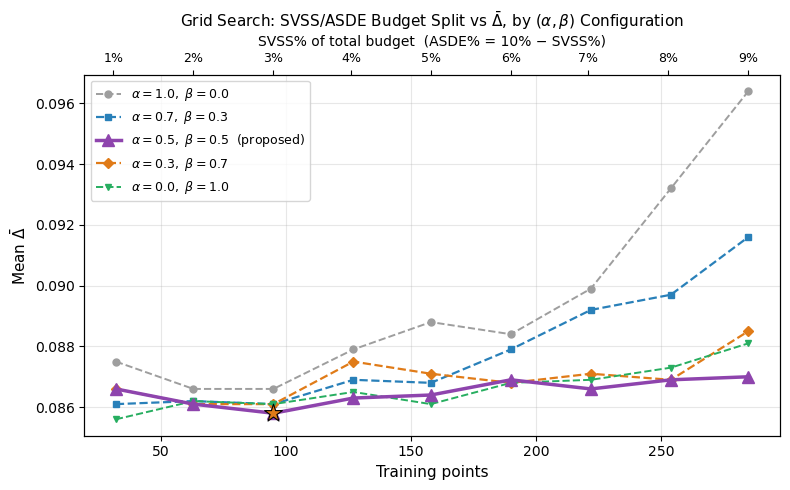

In [1]:
import pandas as pd, matplotlib.pyplot as plt

svts = pd.read_csv("svts_sde_split_grid.csv")
MAX_N = 317
svts["SVTS_pts"] = (svts.SVTS_pct / 10 * MAX_N).round().astype(int)

WANG_SDE_DELTA = 0.0804
BEST_ALPHA, BEST_BETA, BEST_PCT = 0.5, 0.5, 3

configs = [
    (1.0, 0.0, "#9E9E9E", "o", "--", 1.4, r"$\alpha=1.0,\ \beta=0.0$"),
    (0.7, 0.3, "#2980B9", "s", "--", 1.6, r"$\alpha=0.7,\ \beta=0.3$"),
    (0.5, 0.5, "#8E44AD", "^", "-", 2.5, r"$\alpha=0.5,\ \beta=0.5$  (proposed)"),
    (0.3, 0.7, "#E07B18", "D", "--", 1.6, r"$\alpha=0.3,\ \beta=0.7$"),
    (0.0, 1.0, "#27AE60", "v", "--", 1.4, r"$\alpha=0.0,\ \beta=1.0$"),
]

fig, ax = plt.subplots(figsize=(8, 5))

for a, b, color, marker, ls, lw, label in configs:
    sub = svts[(svts.alpha == a) & (svts.beta == b)].sort_values("SVTS_pts")
    ms = 8 if (a, b) == (0.5, 0.5) else 5
    ax.plot(
        sub.SVTS_pts,
        sub.Delta,
        color=color,
        marker=marker,
        linestyle=ls,
        linewidth=lw,
        markersize=ms,
        label=label,
        zorder=6 if (a, b) == (0.5, 0.5) else 3,
    )



best_row = svts[
    (svts.alpha == BEST_ALPHA) & (svts.beta == BEST_BETA) & (svts.SVTS_pct == BEST_PCT)
]
if not best_row.empty:
    ax.scatter(
        best_row.SVTS_pts.values[0],
        best_row.Delta.values[0],
        color="#E07B18",
        s=180,
        zorder=10,
        marker="*",
        edgecolors="black",
        linewidths=0.8,
    )




ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ticks_pts = [int(p / 10 * MAX_N) for p in range(1, 10)]
ax2.set_xticks(ticks_pts)
ax2.set_xticklabels([f"{p}%" for p in range(1, 10)], fontsize=9)
ax2.set_xlabel("SVSS% of total budget  (ASDE% = 10% − SVSS%)", fontsize=10)

ax.set_xlabel("Training points", fontsize=11)
ax.set_ylabel(r"Mean $\bar{\Delta}$", fontsize=11)
ax.set_title(
    r"Grid Search: SVSS/ASDE Budget Split vs $\bar{\Delta}$, by $(\alpha,\beta)$ Configuration",
    fontsize=11,
)
ax.legend(fontsize=9, loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("svts_sde_split_delta.pdf", dpi=200, bbox_inches="tight")
print("Saved svts_sde_split_delta.pdf")


In [ ]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import warnings, random, numpy as np, pandas as pd, GPy

warnings.filterwarnings("ignore")
GPy.util.linalg.jitchol_MAXTRIES = 20

ROOT_FOLDER = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/FPGA DATA/Raw-data_exahaustive"
CALIB_FPGA = 1
NUM_PATHS = 32
TRAIN_RATIO = 0.10
SEED = 42

SVTS_ALPHA, SVTS_BETA = 0.7, 0.3
HYB_ALPHA, HYB_BETA = 0.5, 0.5
HYB_SVTS_RATIO = 0.03
K_NEIGHBORS = 2
ROUGHNESS_THRESH = 2.0
SDE_ALPHA, SDE_BETA = 2, 2


def load_dat(path):
    grid = np.loadtxt(path, delimiter=",")
    rows, cols = grid.shape
    rec = [
        (x, y, grid[y, x])
        for y in range(rows)
        for x in range(cols)
        if grid[y, x] != 0.0
    ]
    df = pd.DataFrame(rec, columns=["X", "Y", "Value"])
    med, std = df.Value.median(), df.Value.std()
    return df[np.abs(df.Value - med) <= 3 * std].reset_index(drop=True)


def evaluate(df, train_idx):
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    test_idx = [i for i in range(len(df)) if i not in train_idx]
    m = GPy.models.GPRegression(
        X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
    )
    m.optimize(messages=False)
    pred, _ = m.predict(X[test_idx])
    true = Y[test_idx]
    rmsd = np.sqrt(np.mean((pred.flatten() - true) ** 2))
    dspec = Y.max() - Y.min()
    delta = np.mean(np.abs(pred.flatten() - true)) / dspec
    return rmsd, delta


def get_checkpoints(n_active):
    step = max(1, round(n_active * 0.01))
    n_train = int(n_active * TRAIN_RATIO)
    cps = sorted(set(min(step * i, n_train) for i in range(1, 11)))
    return step, n_train, cps


# ---------------- Raw AL (min-variance, matches raw_al.py) ----------------
def al_curve(df, n_train, checkpoints, rng):
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    idx_all = np.arange(len(df))
    train_idx = [rng.choice(idx_all)]
    results = []
    while len(train_idx) < n_train:
        remaining = np.setdiff1d(idx_all, train_idx)
        m = GPy.models.GPRegression(
            X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        _, var = m.predict(X[remaining])
        train_idx.append(remaining[np.argmin(var.ravel())])
        if len(train_idx) in checkpoints:
            r, d = evaluate(df, train_idx)
            results.append((len(train_idx), r, d))
    return results


# ---------------- SVTS growth (matches svts.py / hybrid_svts_sde.py's svts_select) ----------------
def svts_grow(df, target, rng, alpha, beta, checkpoints=None, results=None):
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    idx_all = np.arange(len(df))
    train_idx = [rng.choice(idx_all)]
    if checkpoints is not None and len(train_idx) in checkpoints:
        r, d = evaluate(df, train_idx)
        results.append((len(train_idx), r, d))
    while len(train_idx) < target:
        remaining = np.setdiff1d(idx_all, train_idx)
        m = GPy.models.GPRegression(
            X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        mean_r, var_r = m.predict(X[remaining])
        mean_s, var_s = m.predict(X[train_idx])
        all_mean = np.concatenate([mean_r.ravel(), mean_s.ravel()])
        all_var = np.concatenate([var_r.ravel(), var_s.ravel()])
        mean_z = (all_mean - all_mean.mean()) / (all_mean.std() + 1e-9)
        var_z = (all_var - all_var.mean()) / (all_var.std() + 1e-9)
        n_r = len(mean_r)
        feat_r = np.column_stack([mean_z[:n_r], var_z[:n_r]])
        feat_s = np.column_stack([mean_z[n_r:], var_z[n_r:]])
        centroid = feat_s.mean(axis=0)
        centroid_c = centroid - centroid.mean()
        feat_r_c = feat_r - feat_r.mean(axis=1, keepdims=True)
        sim = (feat_r_c @ centroid_c) / (
            np.linalg.norm(feat_r_c, axis=1) * np.linalg.norm(centroid_c) + 1e-9
        )
        sim_n = (sim - sim.min()) / (sim.max() - sim.min() + 1e-9)
        var_n = (var_r.ravel() - var_r.min()) / (var_r.max() - var_r.min() + 1e-9)
        score = alpha * sim_n + beta * var_n
        train_idx.append(remaining[np.argmax(score)])
        if checkpoints is not None and len(train_idx) in checkpoints:
            r, d = evaluate(df, train_idx)
            results.append((len(train_idx), r, d))
    return train_idx


def svts_curve(df, n_train, checkpoints, rng, alpha, beta):
    results = []
    svts_grow(df, n_train, rng, alpha, beta, checkpoints, results)
    return results


# ---------------- Raw SDE (fixed alpha=2,beta=2, matches sde.py, single shuffle) ----------------
def sde_curve(df, n_train, checkpoints, seed):
    idx_all = list(range(len(df)))
    random.Random(seed).shuffle(idx_all)
    train_idx = [idx_all[0]]
    results = []
    if len(train_idx) in checkpoints:
        r, d = evaluate(df, train_idx)
        results.append((len(train_idx), r, d))
    xs, ys = df.X.values, df.Y.values
    leftover = []
    for idx in idx_all[1:]:
        if len(train_idx) >= n_train:
            break
        if all(
            abs(xs[idx] - xs[s]) > SDE_ALPHA or abs(ys[idx] - ys[s]) > SDE_BETA
            for s in train_idx
        ):
            train_idx.append(idx)
            if len(train_idx) in checkpoints:
                r, d = evaluate(df, train_idx)
                results.append((len(train_idx), r, d))
        else:
            leftover.append(idx)
    if len(train_idx) < n_train:
        train_idx += leftover[: n_train - len(train_idx)]
        r, d = evaluate(df, train_idx)
        results.append((len(train_idx), r, d))
    return results


# ---------------- Adaptive SDE (matches hybrid_svts_sde.py's adaptive_sde exactly) ----------------
def adaptive_sde_grow(df, train_idx, n_train, seed, checkpoints=None, results=None):
    ab = {}
    for j in train_idx:
        xj, yj = df.loc[j, "X"], df.loc[j, "Y"]
        others = sorted(
            [p for p in train_idx if p != j],
            key=lambda p: (df.loc[p, "X"] - xj) ** 2 + (df.loc[p, "Y"] - yj) ** 2,
        )
        nn = others[:K_NEIGHBORS]
        if not nn:
            ab[j] = (1, 1)
            continue
        dx = np.mean([abs(df.loc[p, "X"] - xj) for p in nn])
        dy = np.mean([abs(df.loc[p, "Y"] - yj) for p in nn])
        bump = 1 if np.std([df.loc[p, "Value"] for p in nn]) > ROUGHNESS_THRESH else 0
        ab[j] = (int(np.ceil(dx)) + bump, int(np.ceil(dy)) + bump)
    default_ab = (
        int(np.mean([v[0] for v in ab.values()])),
        int(np.mean([v[1] for v in ab.values()])),
    )
    selected = list(train_idx)
    for i in np.random.RandomState(seed).permutation(df.index):
        if i in selected or len(selected) >= n_train:
            continue
        x, y = df.loc[i, "X"], df.loc[i, "Y"]
        if all(
            abs(df.loc[j, "X"] - x) > ab.get(j, default_ab)[0]
            or abs(df.loc[j, "Y"] - y) > ab.get(j, default_ab)[1]
            for j in selected
        ):
            selected.append(i)
            ab[i] = default_ab
            if checkpoints is not None and len(selected) in checkpoints:
                r, d = evaluate(df, selected)
                results.append((len(selected), r, d))
    if len(selected) < n_train:
        leftover = [
            i
            for i in np.random.RandomState(seed).permutation(df.index)
            if i not in selected
        ]
        selected += leftover[: n_train - len(selected)]
        if checkpoints is not None:
            r, d = evaluate(df, selected)
            results.append((len(selected), r, d))
    return selected


# ---------------- Hybrid SVTS+SDE (SVTS phase 3% then Adaptive SDE phase 7%) ----------------
def hybrid_curve(df, n_train, checkpoints, rng, alpha, beta, svts_ratio, seed):
    svts_target = max(1, round(len(df) * svts_ratio))
    results = []
    train_idx = svts_grow(df, svts_target, rng, alpha, beta, checkpoints, results)
    adaptive_sde_grow(df, train_idx, n_train, seed, checkpoints, results)
    return results


al_all, svts_all, sde_all, hyb_all = {}, {}, {}, {}
for path in range(1, NUM_PATHS + 1):
    df = load_dat(f"{ROOT_FOLDER}/FPGA-{CALIB_FPGA}/data{path}.dat")
    n_active = len(df)
    step, n_train, checkpoints = get_checkpoints(n_active)
    checkpoints = set(checkpoints)

    for n, r, d in al_curve(df, n_train, checkpoints, np.random.default_rng(SEED)):
        al_all.setdefault(n, []).append((r, d))
    for n, r, d in svts_curve(
        df, n_train, checkpoints, np.random.default_rng(SEED), SVTS_ALPHA, SVTS_BETA
    ):
        svts_all.setdefault(n, []).append((r, d))
    for n, r, d in sde_curve(df, n_train, checkpoints, SEED):
        sde_all.setdefault(n, []).append((r, d))
    for n, r, d in hybrid_curve(
        df,
        n_train,
        checkpoints,
        np.random.default_rng(SEED),
        HYB_ALPHA,
        HYB_BETA,
        HYB_SVTS_RATIO,
        SEED,
    ):
        hyb_all.setdefault(n, []).append((r, d))
    print(f"path {path} done (step={step}, n_train={n_train})")

for name, data in [
    ("Raw AL", al_all),
    ("SVTS (a=0.7,b=0.3)", svts_all),
    ("SDE", sde_all),
    ("Hybrid SVTS+SDE", hyb_all),
]:
    print(f"\n{name}")
    print(f"{'n_pts':>6} {'RMSD':>8} {'Delta':>8}")
    for n in sorted(data):
        rs = [x[0] for x in data[n]]
        ds = [x[1] for x in data[n]]
        print(f"{n:>6} {np.mean(rs):>8.4f} {np.mean(ds):>8.4f}")

path 1 done
path 2 done
path 3 done
path 4 done
path 5 done
path 6 done
path 7 done
path 8 done
path 9 done
path 10 done
path 11 done
path 12 done
path 13 done
path 14 done
path 15 done
path 16 done
path 17 done
path 18 done
path 19 done
path 20 done
path 21 done
path 22 done
path 23 done
path 24 done
path 25 done
path 26 done
path 27 done
path 28 done
path 29 done
path 30 done
path 31 done
path 32 done

Raw AL
 n_pts     RMSD    Delta
    17   2.7666   0.1575
    34   2.6317   0.1467
    50   2.6110   0.1454
    67   2.5635   0.1431
    83   2.4668   0.2182
    84   2.5363   0.1390
   100   2.5657   0.1433
   116   2.4244   0.2141
   117   2.5458   0.1395
   133   2.3778   0.2095
   134   2.5123   0.1374
   149   2.3739   0.2091
   150   2.5255   0.1380
   166   2.3820   0.2100
   167   2.5388   0.1386
   182   2.3827   0.2101
   183   2.5518   0.1391
   199   2.3572   0.2075
   200   2.5646   0.1394
   215   2.3402   0.2057
   217   2.5599   0.1389
   232   2.3677   0.2087
   233   2

In [2]:
import pandas as pd, matplotlib.pyplot as plt

FILES = {
    "Raw AL": "raw_al.csv",
    "SVTS (a=0.7,b=0.3)": "svts.csv",
    "SDE": "sde.csv",
    "Hybrid SVTS+SDE": "hybrid_svts_sde.csv",
}

plt.figure(figsize=(9, 6))
for method, f in FILES.items():
    df = pd.read_csv(f)
    plt.plot(df.n_pts, df.Delta, marker="o", markersize=4, label=method)

plt.xlabel("Number of training points")
plt.ylabel("Delta")
plt.title("Convergence comparison: Raw AL, SVTS, SDE, Hybrid SVTS+SDE")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("all_methods_convergence.png", dpi=200, bbox_inches="tight")
plt.close()
print("saved")


saved
